# BreastDCEDL
## BreastDCEDL Data Explore and Visualize



In [1]:
from sklearn.metrics import classification_report,auc,roc_auc_score
from PIL import Image
import time
from pathlib import Path


import os
import numpy as np
import pandas as pd
from PIL import Image


import warnings
warnings.filterwarnings('ignore', '.*do not.*', )
warnings.warn('Do not show this message')

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from glob import glob
#from skimage import io
from sklearn.utils import shuffle

#from nipype.interfaces.ants import N4BiasFieldCorrection
import sys
import os
import ast
import re
import nibabel as nib
import warnings
warnings.filterwarnings('ignore')

In [2]:
def show_n_images(
    imgs,
    cmap="gray",
    titles=None,
    enlarge=4,
    mtitle=None,
    cut=False,
    axis_off=True,
    fontsize=15,
    cb=False,
):
    """Visualise *n* images side-by-side."""
    _ = plt.figure(figsize=(enlarge * len(imgs), enlarge * 2))
    for i, im in enumerate(imgs, 1):
        ax = plt.subplot(1, len(imgs), i)
        if cb and len(np.unique(im)) > 5:
            im = cont_br(im)
        ax.imshow(im[50:290, 75:450] if cut else im, cmap=cmap, origin="lower")
        if titles is not None:
            ax.set_title(titles[i - 1], fontsize=fontsize)
        if axis_off:
            ax.axis("off")
    if mtitle:
        plt.suptitle(mtitle, fontsize=fontsize + 2)
    plt.tight_layout(); plt.show()


In [ ]:


def _ds_from_pid(pid: str) -> str:
    if "ISPY1" in pid:
        return "spy1"
    if ("ISPY2" in pid) or ("ACRIN-6698" in pid):
        return "spy2"
    if "Breast_MRI" in pid:
        return "duke"
    raise ValueError(f"Cannot infer dataset for pid={pid!r}")




def read_nifti(path: str) -> np.ndarray:
    return nib.load(path).get_fdata()

def _last_int(path):
    m = re.search(r"(\d+)\.nii\.gz$", path)
    return int(m.group(1)) if m else -1


def get_all_nifti_acquisitions(pid):



    dpath = nifti_path


    ff = [x for x in os.listdir(dpath) if pid in x]
    if len(ff)==0: return None
    if deb:print(os.listdir(dpath)[:7],pid)
    if deb:print(ff)


    img = []
    for f in ff:
        x = read_nifti(os.path.join(dpath, f))
        img.append(x)

    return img

def get_sorted_nifti_acquisitions(pid):



    ff = [x for x in os.listdir(nifti_path) if pid in x]
    if len(ff)==0: return None
    if deb:print(os.listdir(nifti_path)[:7],pid)
    if deb:print(ff)
    sorted_filenames = sorted(ff, key=_last_int)

    img = []
    for f in sorted_filenames:
        x = read_nifti(os.path.join(nifti_path, f))
        img.append(x)

    return img


def get_nifti_mask(pid: str):


    mpath=mask_path

    ff = [x for x in os.listdir(mpath) if pid in x]

    if deb:print(ff)
    if len(ff)==0: return None

    f=ff[0]


    x = read_nifti(os.path.join(mpath, f))


    return x


In [4]:
def minmax(m):
    if m.max()==0:
        return m
    m = (m-m.min())/(m.max()-m.min())
    return m

def to_rgb(a,b,c):

    stack_axis = a.ndim

    # Stack along the next axis
    im = np.stack([minmax(a), minmax(b), minmax(c)], axis=stack_axis)

    return im

In [ ]:
!tar -xvzf BreastDCEDL_demo_data.tar.gz

BreastDCEDL_demo_data/
BreastDCEDL_demo_data/dce/
BreastDCEDL_demo_data/dce/Breast_MRI_002_duke_dce_aqc_3.nii.gz
BreastDCEDL_demo_data/dce/Breast_MRI_001_duke_dce_aqc_0.nii.gz
BreastDCEDL_demo_data/dce/Breast_MRI_001_duke_dce_aqc_1.nii.gz
BreastDCEDL_demo_data/dce/Breast_MRI_001_duke_dce_aqc_3.nii.gz
BreastDCEDL_demo_data/dce/Breast_MRI_002_duke_dce_aqc_0.nii.gz
BreastDCEDL_demo_data/dce/Breast_MRI_002_duke_dce_aqc_1.nii.gz
BreastDCEDL_demo_data/dce/ISPY1_1003_spy1_vis1_dce_aqc_2.nii.gz
BreastDCEDL_demo_data/dce/ISPY1_1001_spy1_vis1_dce_aqc_0.nii.gz
BreastDCEDL_demo_data/dce/ISPY1_1001_spy1_vis1_dce_aqc_1.nii.gz
BreastDCEDL_demo_data/dce/ISPY1_1001_spy1_vis1_dce_aqc_2.nii.gz
BreastDCEDL_demo_data/dce/ISPY1_1002_spy1_vis1_dce_aqc_0.nii.gz
BreastDCEDL_demo_data/dce/ISPY1_1002_spy1_vis1_dce_aqc_1.nii.gz
BreastDCEDL_demo_data/dce/ISPY1_1002_spy1_vis1_dce_aqc_2.nii.gz
BreastDCEDL_demo_data/dce/ISPY1_1003_spy1_vis1_dce_aqc_0.nii.gz
BreastDCEDL_demo_data/dce/ISPY1_1003_spy1_vis1_dce_aqc_1.nii

In [10]:
# set to base of your local nifti data
data_path="BreastDCEDL_demo_data"

In [11]:
nifti_path = os.path.join(data_path,'dce')
mask_path = os.path.join(data_path,'mask')

## Load and view metada

In [15]:
df=pd.read_csv('BreastDCEDL_metadata_min_crop.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2070 entries, 0 to 2069
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   pid             2070 non-null   object 
 1   pCR             1452 non-null   float64
 2   n_xy            2070 non-null   float64
 3   n_z             2070 non-null   float64
 4   n_times         2070 non-null   float64
 5   pre             2070 non-null   float64
 6   post_early      2070 non-null   float64
 7   post_late       2070 non-null   float64
 8   slice_thick     2070 non-null   float64
 9   xy_spacing      2070 non-null   float64
 10  mask_start      2070 non-null   float64
 11  mask_end        2070 non-null   float64
 12  sraw            2070 non-null   float64
 13  eraw            2070 non-null   float64
 14  scol            2070 non-null   float64
 15  ecol            2070 non-null   float64
 16  tum_vol         2067 non-null   float64
 17  age             2067 non-null   f

## I-SPY-2 example

In [ ]:
nifti_path

'BreastDCEDL_demo_data/BreastDCEDL_demo_data/dce'

In [ ]:
pids=[]
deb=1
for i,row in df.iterrows():

    if get_all_nifti_acquisitions(row['pid']) is not None:
        print(row['pid'])
        pids.append(row['pid'])

pids

['ISPY1_1003_spy1_vis1_dce_aqc_2.nii.gz', 'ACRIN-6698-102212_spy2_vis1_dce_aqc_0.nii.gz', 'Breast_MRI_002_duke_dce_aqc_3.nii.gz', 'ISPY1_1001_spy1_vis1_dce_aqc_2.nii.gz', 'Breast_MRI_002_duke_dce_aqc_0.nii.gz', 'ISPY1_1003_spy1_vis1_dce_aqc_1.nii.gz', 'ISPY1_1002_spy1_vis1_dce_aqc_0.nii.gz'] ACRIN-6698-102212
['ACRIN-6698-102212_spy2_vis1_dce_aqc_0.nii.gz', 'ACRIN-6698-102212_spy2_vis1_dce_aqc_6.nii.gz', 'ACRIN-6698-102212_spy2_vis1_dce_aqc_2.nii.gz']
ACRIN-6698-102212
['ISPY1_1003_spy1_vis1_dce_aqc_2.nii.gz', 'ACRIN-6698-102212_spy2_vis1_dce_aqc_0.nii.gz', 'Breast_MRI_002_duke_dce_aqc_3.nii.gz', 'ISPY1_1001_spy1_vis1_dce_aqc_2.nii.gz', 'Breast_MRI_002_duke_dce_aqc_0.nii.gz', 'ISPY1_1003_spy1_vis1_dce_aqc_1.nii.gz', 'ISPY1_1002_spy1_vis1_dce_aqc_0.nii.gz'] ACRIN-6698-103939
['ACRIN-6698-103939_spy2_vis1_dce_aqc_0.nii.gz', 'ACRIN-6698-103939_spy2_vis1_dce_aqc_2.nii.gz', 'ACRIN-6698-103939_spy2_vis1_dce_aqc_5.nii.gz']
ACRIN-6698-103939
['ISPY1_1003_spy1_vis1_dce_aqc_2.nii.gz', 'ACRIN-669

['ACRIN-6698-102212',
 'ACRIN-6698-103939',
 'Breast_MRI_001',
 'Breast_MRI_002',
 'ISPY1_1003',
 'ISPY1_1001',
 'ISPY1_1002']

In [ ]:
df[df.pid.isin(pids)]

,pid,pCR,n_xy,n_z,n_times,pre,post_early,post_late,slice_thick,xy_spacing,...,race_white,race_black,HR,HER2,HR_HER2_STATUS,TripleNeg,HER2pos,HRposHER2neg,dataset,test
0,ACRIN-6698-102212,0.0,256.0,38.0,8.0,0.0,2.0,6.0,2.0,0.605500,...,1.0,0.0,0.0,0.0,TripleNeg,1.0,0.0,0.0,spy2,1.0
1,ACRIN-6698-103939,0.0,256.0,25.0,7.0,0.0,2.0,5.0,2.5,0.585900,...,1.0,0.0,1.0,0.0,HRposHER2neg,0.0,0.0,1.0,spy2,0.0
982,Breast_MRI_001,0.0,256.0,24.0,5.0,0.0,1.0,4.0,1.1,0.803571,...,0.0,1.0,0.0,1.0,HER2pos,0.0,1.0,0.0,duke,0.0
983,Breast_MRI_002,0.0,256.0,14.0,4.0,0.0,1.0,3.0,1.3,0.585900,...,0.0,1.0,0.0,0.0,TripleNeg,1.0,0.0,0.0,duke,1.0
1918,ISPY1_1003,0.0,256.0,26.0,3.0,0.0,1.0,2.0,2.0,0.781250,...,1.0,0.0,1.0,0.0,HRposHER2neg,0.0,0.0,1.0,spy1,0.0
1925,ISPY1_1001,0.0,256.0,30.0,3.0,0.0,1.0,2.0,2.0,0.781250,...,1.0,0.0,1.0,0.0,HRposHER2neg,0.0,0.0,1.0,spy1,0.0
1958,ISPY1_1002,0.0,256.0,22.0,3.0,0.0,1.0,2.0,2.0,0.781250,...,1.0,0.0,1.0,0.0,HRposHER2neg,0.0,0.0,1.0,spy1,0.0


In [ ]:
duke_pids=[p for p in pids if 'Breast_MRI' in p]


In [ ]:
deb=0

dce 38 256 (42, 256, 256) mask:  2 39 (42, 256, 256)


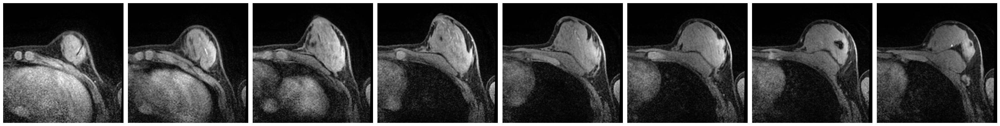

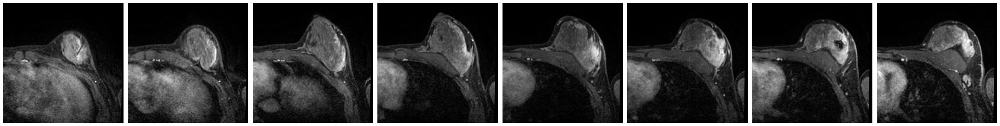

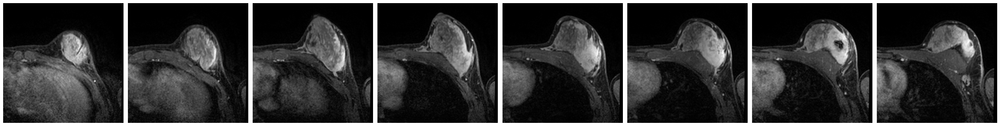

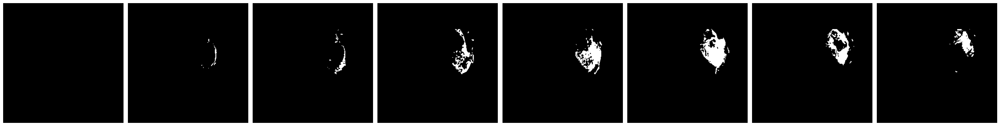

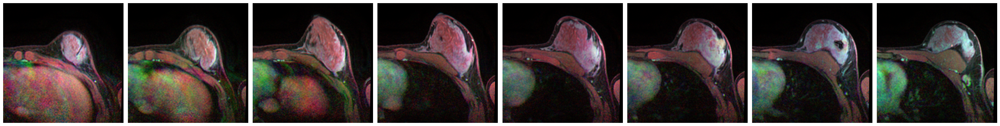

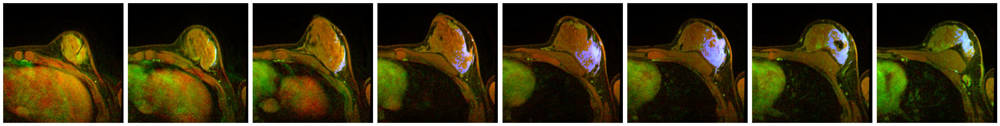

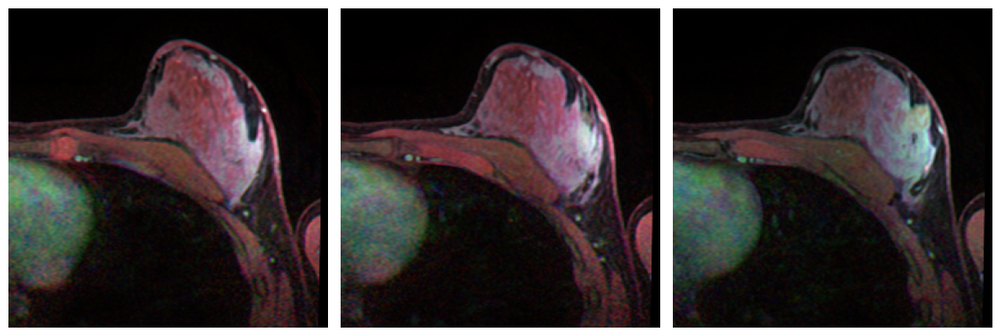

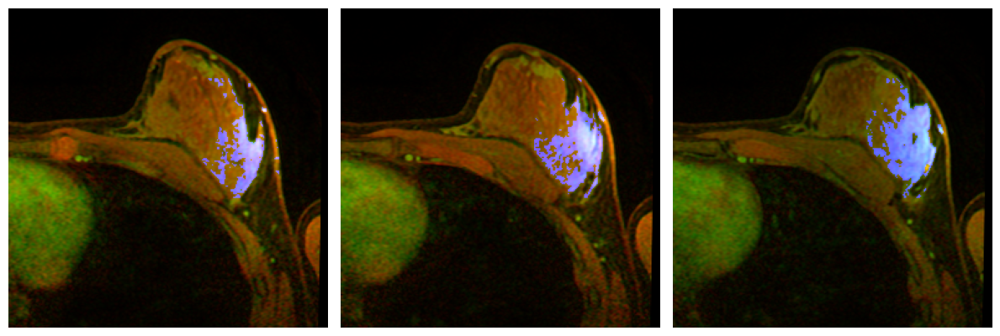

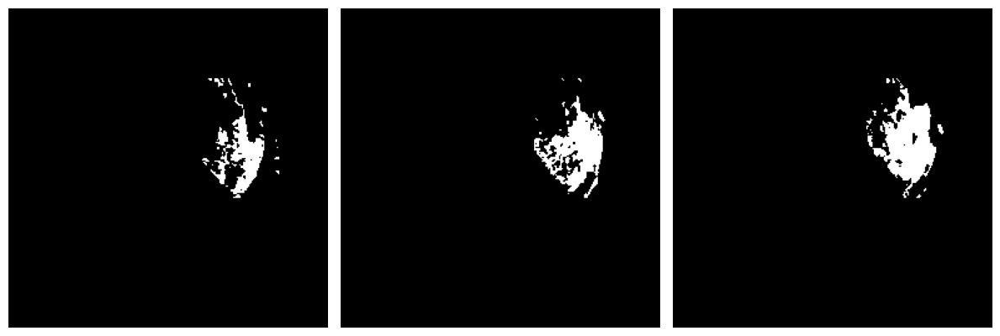

In [ ]:


        pid=pids[0]

        row = df[df.pid==pid].iloc[0]
        smask=int(row['mask_start'])
        emask = int(row['mask_end'])
        pmask = (smask+emask)//2
        nz=int(row['n_z'])
        nxy=int(row['n_xy'])


        d=get_sorted_nifti_acquisitions(pid)
        m = get_nifti_mask(pid)

        print('dce',nz,nxy,d[0].shape, 'mask: ', smask,emask,  m.shape)

        show_n_images([d[0][k] for k in range(0,nz,5)])
        show_n_images([d[1][k] for k in range(0,nz,5)])
        show_n_images([d[2][k] for k in range(0,nz,5)])
        show_n_images([m[k] for k in range(0,nz,5)])
        show_n_images([to_rgb(d[0][k],d[1][k], d[2][k]) for k in range(0,nz,5)])
        show_n_images([to_rgb(d[0][k],d[1][k], m[k]) for k in range(0,nz,5)])
        show_n_images([to_rgb(d[0][k],d[1][k], d[2][k]) for k in [pmask-3,pmask,pmask+3]])
        show_n_images([to_rgb(d[0][k],d[1][k], m[k]) for k in [pmask-3,pmask,pmask+3]])
        show_n_images([ m[k] for k in [pmask-3,pmask,pmask+3]])




=== ACRIN-6698-103939
mask:  2 26


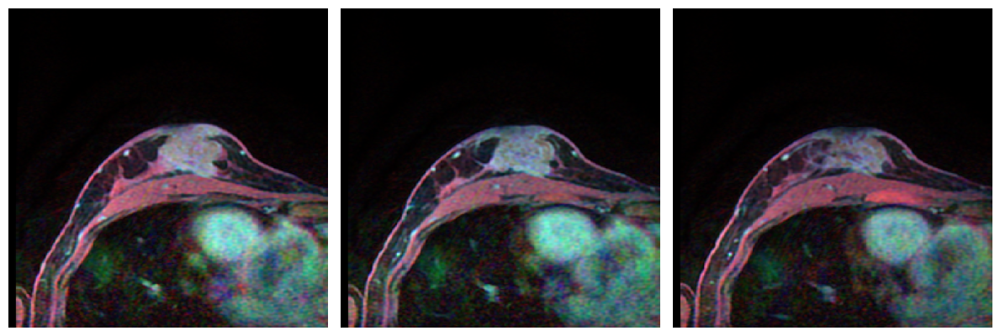

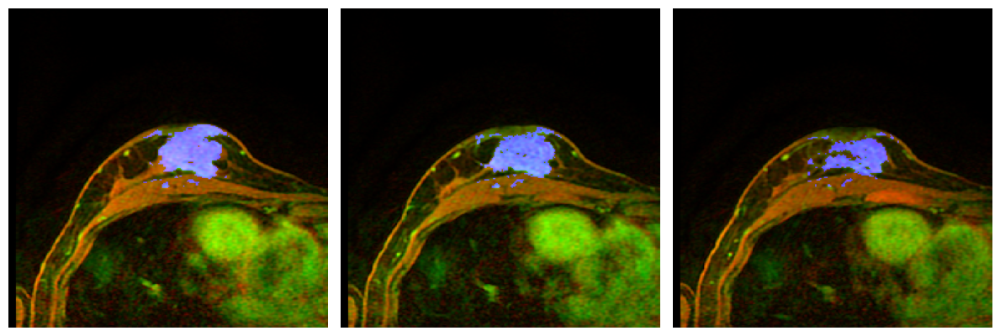

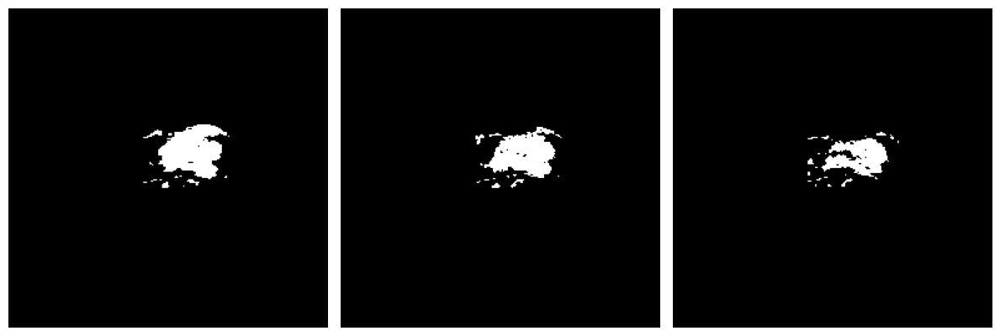

=== ISPY1_1003
mask:  2 23


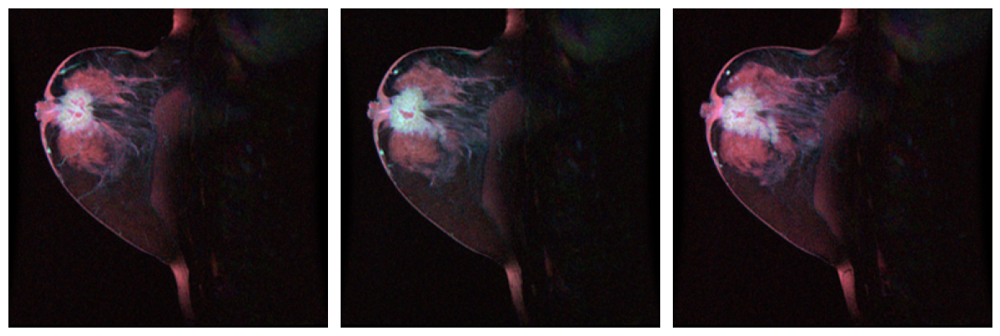

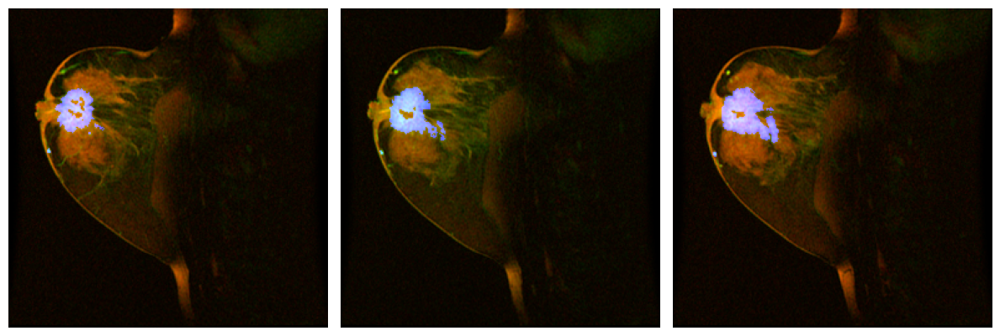

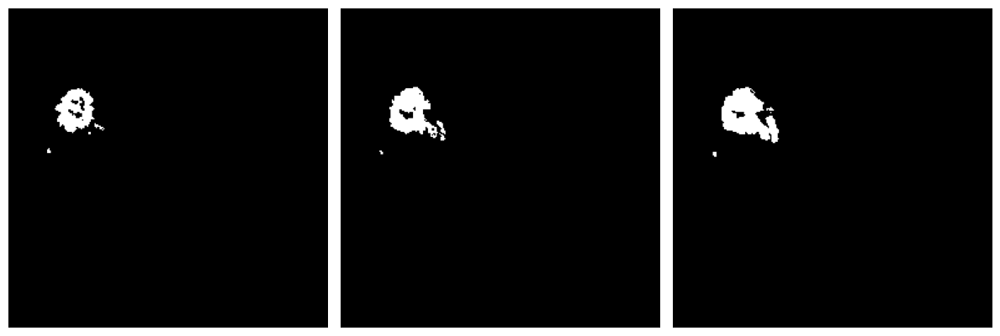

=== ISPY1_1001
mask:  2 27


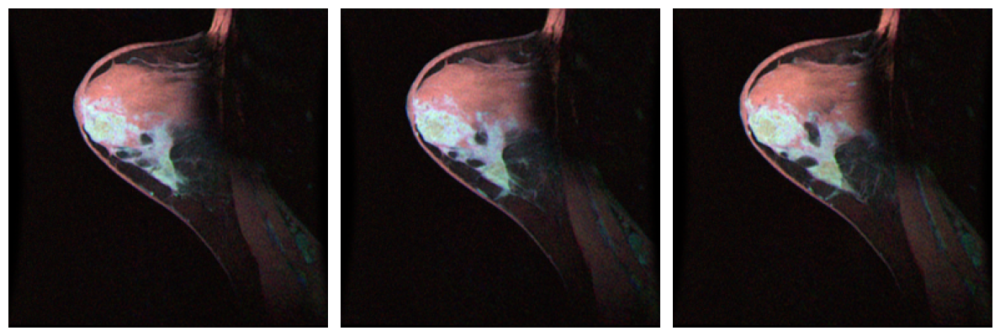

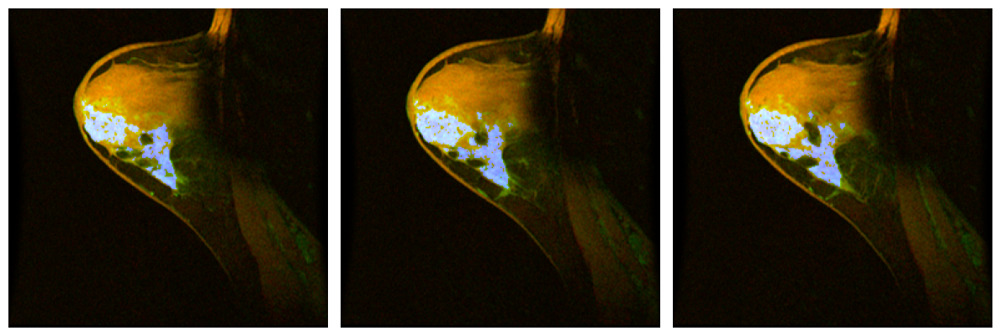

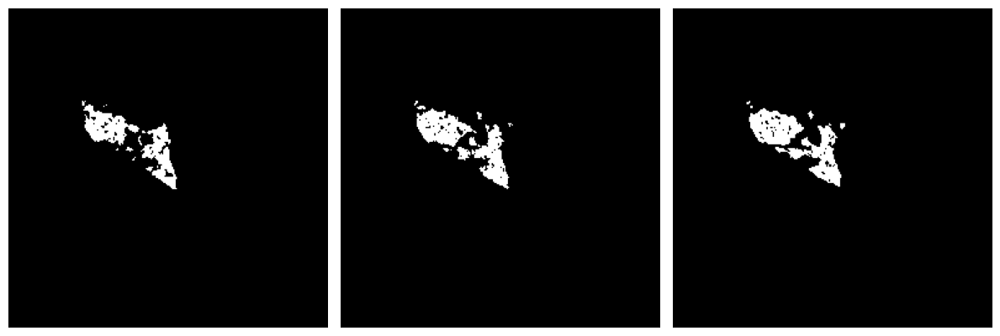

=== ISPY1_1002
mask:  2 19


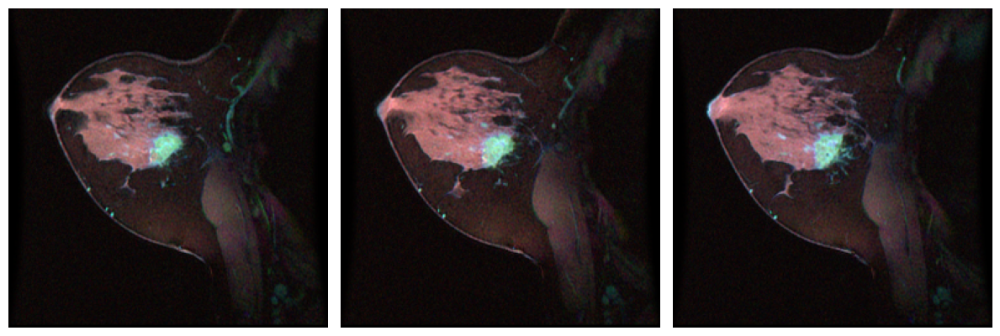

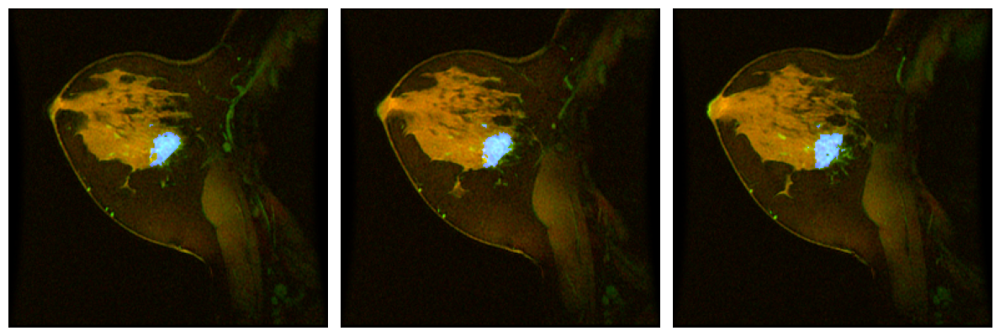

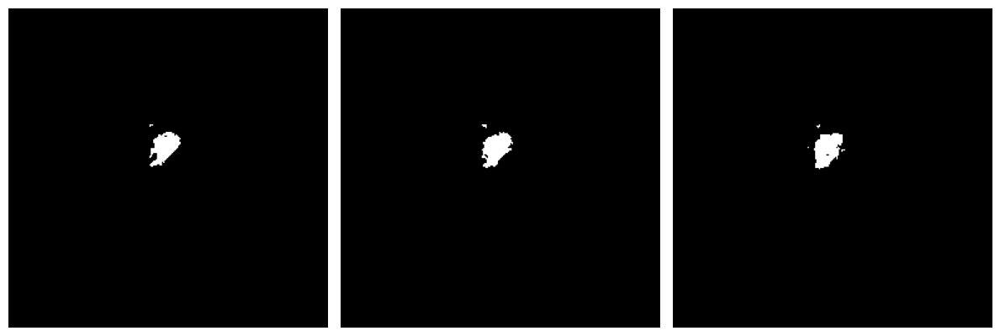

In [ ]:
    for pid in pids[1:]:
        if pid in duke_pids: continue
        print('===',pid)

        row = df[df.pid==pid].iloc[0]
        smask=int(row['mask_start'])
        emask = int(row['mask_end'])
        pmask = (smask+emask)//2
        nz=int(row['n_z'])
        nxy=int(row['n_xy'])
        print('mask: ', smask,emask)

        d=get_sorted_nifti_acquisitions(pid)
        m = get_nifti_mask(pid)

        im=to_rgb(d[0],d[1], d[2])
        show_n_images([to_rgb(d[0][k],d[1][k], d[2][k]) for k in [pmask-1,pmask,pmask+1]])
        show_n_images([to_rgb(d[0][k],d[1][k], m[k]) for k in [pmask-1,pmask,pmask+1]])
        show_n_images([ m[k] for k in [pmask-1,pmask,pmask+1]])





### DUKE example

=== Breast_MRI_001
[  2  25 110 147 117 150]
3 (28, 256, 256)


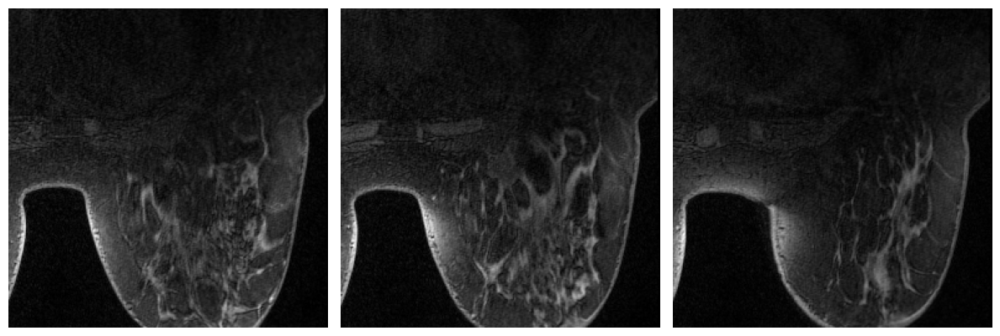

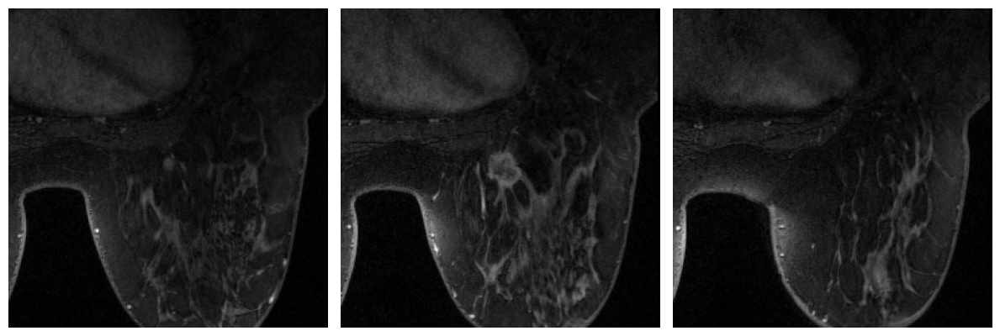

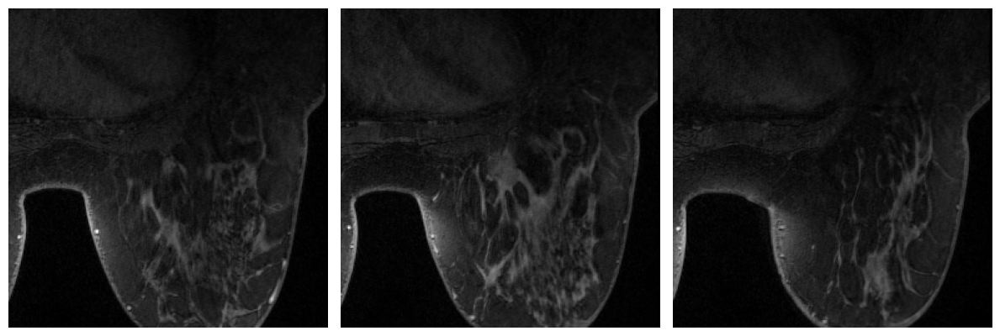

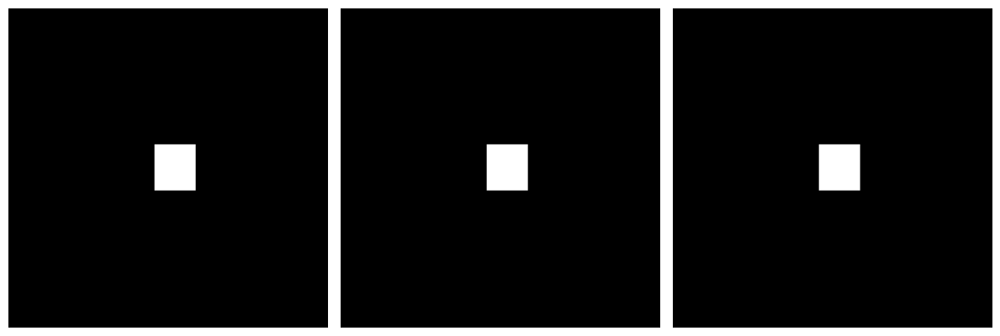

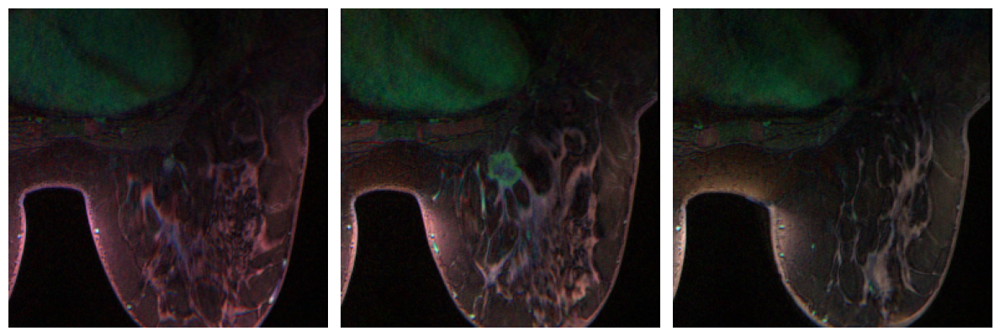

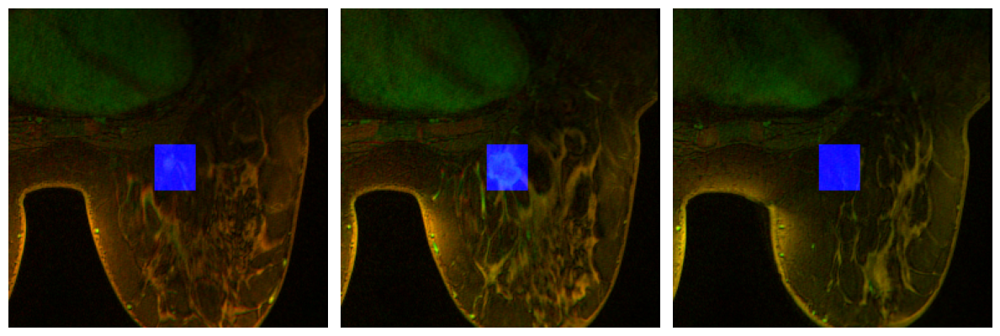

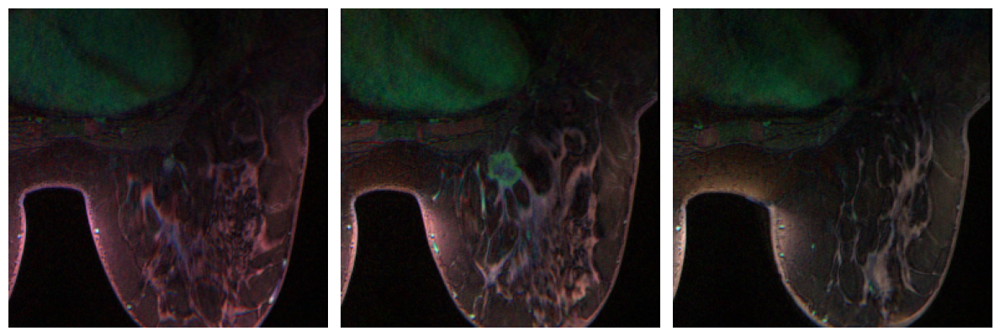

=== Breast_MRI_002
[  2  15 107 150 108 136]
3 (18, 256, 256)


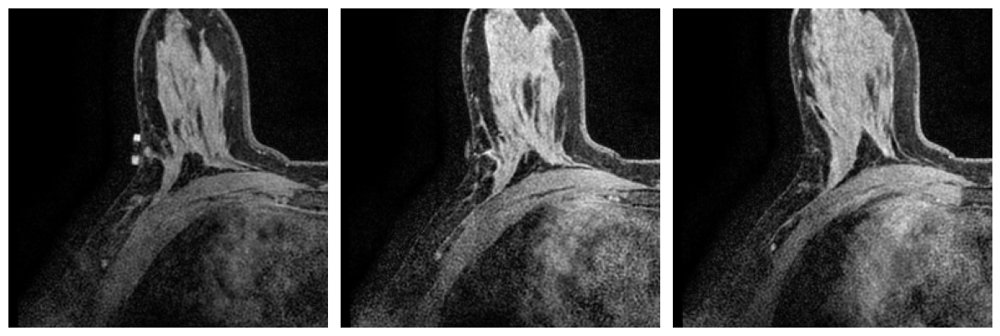

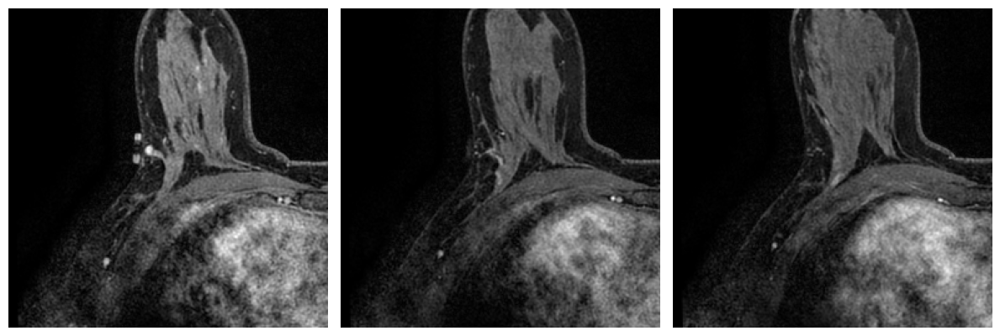

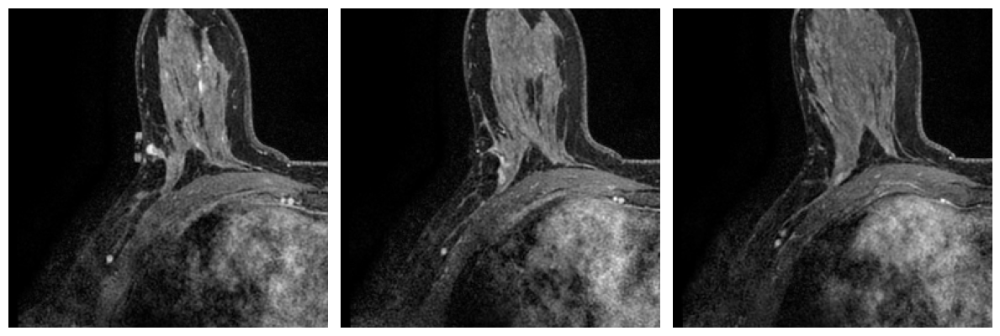

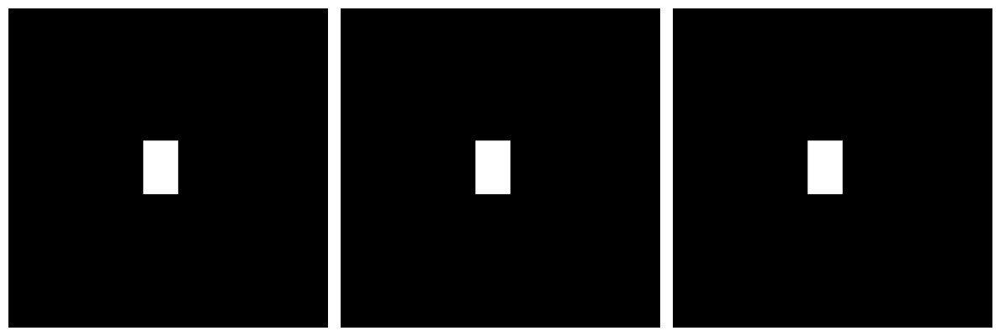

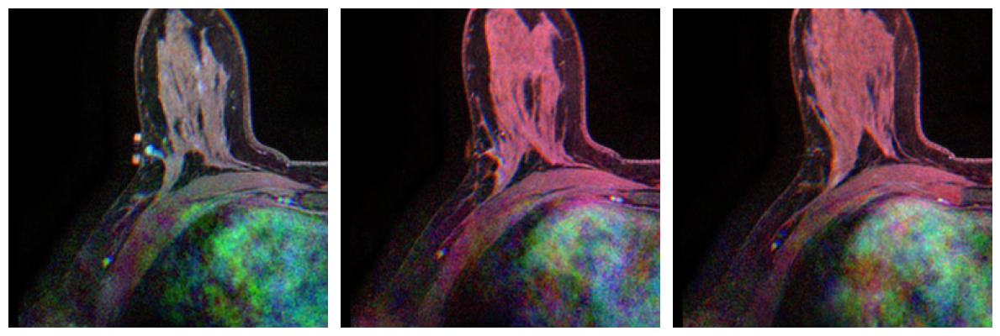

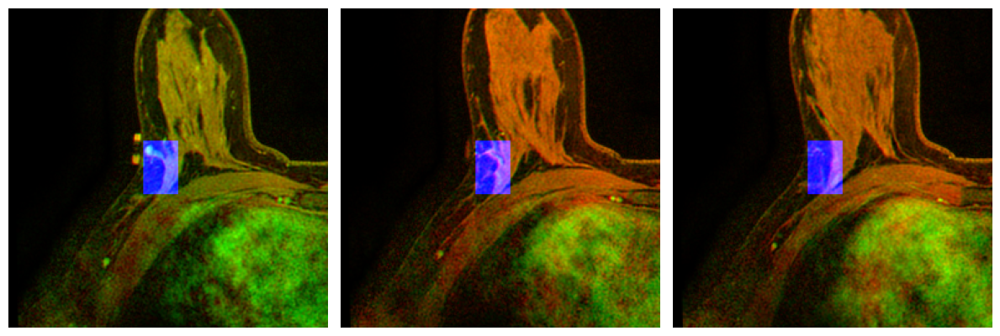

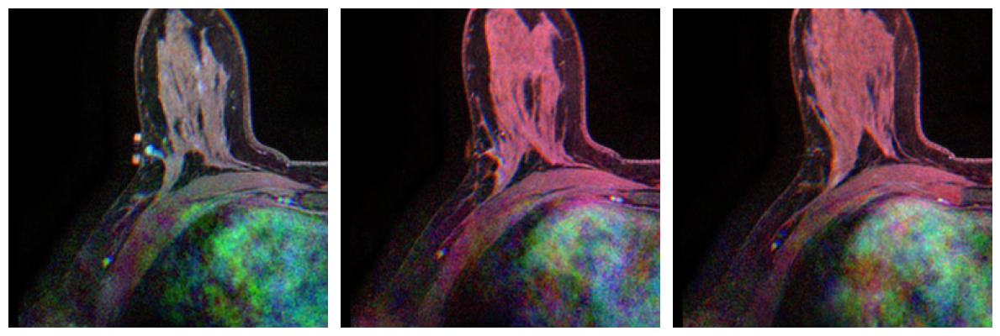

In [ ]:

    for pid in pids[1:]:
        if pid not in duke_pids: continue
        print('===',pid)

        bbox=df[df.pid==pid][['mask_start', 'mask_end',
           'sraw', 'eraw', 'scol', 'ecol']].values[0].astype(int)
        print(bbox)
        d=get_sorted_nifti_acquisitions(pid)
        print(len(d),d[0].shape)
        m=np.zeros(d[0].shape)
        m[bbox[0]:bbox[1], bbox[2]:bbox[3], bbox[4]:bbox[5]]=255
        idx=[bbox[0]+1,(bbox[0]+bbox[1])//2,bbox[1]-1]
        show_n_images([d[0][k] for k in idx],axis_off=True)
        show_n_images([d[1][k] for k in idx],axis_off=True)
        show_n_images([d[2][k] for k in idx],axis_off=True)
        show_n_images([m[k] for k in idx],axis_off=True)

        show_n_images([to_rgb(d[0][k],
                                    d[1][k],d[2][k]) for k in idx],axis_off=True)
        show_n_images([to_rgb(d[0][k],
                                    d[1][k],m[k]) for k in idx],axis_off=True)

        show_n_images([to_rgb(d[0][k],
                                    d[1][k],d[2][k]) for k in idx])
